In [128]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.animation as animation

In [129]:
def get_Voronoi_Cells_from_File(filename):
    file = open(filename)
    fileString = file.read().split("\n")
    file.close()
    Cells = {}
    for i in range(len(fileString) - 1):

        # Retrieve seed ID, seed location, and vertices from output file
        cell_string = fileString[i].split()
        seed_ID = int(cell_string[0])   # seed ID
        seed_loc = np.array([float(cell_string[1]), float(cell_string[2])])     # seed location
        vertices = []
        for j in range(3, len(cell_string)):
            vertex = [float(x) for x in cell_string[j][1:-1].split(",")]
            vertices.append(vertex)
        vertices = np.array(vertices)   # vertices that bound the region

        #  Sort vertices in traversal order
        angles = np.arctan2(vertices[:, 1] - seed_loc[1], vertices[:, 0] - seed_loc[0])
        vertices = vertices[np.argsort(angles)]
        vertices = np.vstack([vertices, vertices[0]])

        # Add to dictionary
        Cells[seed_ID] = {"seed": seed_loc, "vertices": np.column_stack(vertices)}
    return Cells

def get_IDs(Cells):
    return [cell_ID for cell_ID in Cells.keys()]

def get_Seeds(Cells):
    return np.array([cell['seed'] for cell in Cells.values()])

def get_Vertices(Cells):
    return [cell['vertices'] for cell in Cells.values()]

def get_Centroids_from_File(filename):
    file = open(filename)
    fileString = file.read().split()
    file.close()
    centroids = []

    points = [float(x) for x in fileString]
    for i in range(int(len(points)/3)):
        centroids.append(points[3*i+1:3*(i+1)])

    return np.column_stack(centroids)

In [130]:
colors = ["magenta", "blue"]

In [131]:
from matplotlib import rc
rc('animation', html='jshtml')

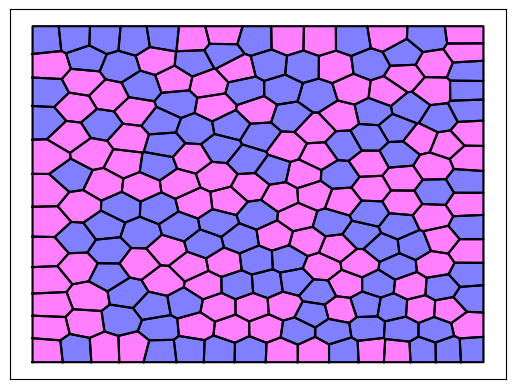

In [132]:
iterations = 30
fig, ax = plt.subplots()
ax.set_xticks([])
ax.set_yticks([])

ims = []
for i in range(iterations+1):
    Cells = get_Voronoi_Cells_from_File(f"output/lloyd/cellset{i}.gnu")
    CIDs = get_IDs(Cells)
    seeds = get_Seeds(Cells)
    vertices = get_Vertices(Cells)
    
    frame_artists = []
    for j in range(len(CIDs)):
        seed_ID, seed_loc, verts = CIDs[j], seeds[j], vertices[j]

        # artist0, = ax.plot(seed_loc[0], seed_loc[1], "o", color="black", zorder=2)
        # frame_artists.append(artist0)
        artist1, = ax.plot(verts[0], verts[1], color="black")
        frame_artists.append(artist1)
        artist2, = ax.fill(verts[0], verts[1], color=colors[seed_ID % len(colors)], alpha=0.5)
        frame_artists.append(artist2)

    ims.append(frame_artists)
    
ani = animation.ArtistAnimation(fig, ims, blit=True)
ani.save("unnamed_2d_animation.gif", writer=animation.PillowWriter(fps=10))

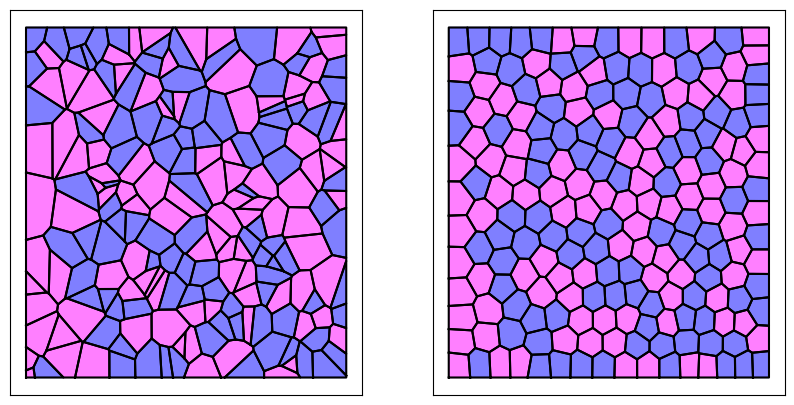

In [133]:
fig, ax = plt.subplots(1,2, figsize=(10,5))
ax[0].set_xticks([])
ax[0].set_yticks([])
ax[1].set_xticks([])
ax[1].set_yticks([])

## Initial seeds
Cells = get_Voronoi_Cells_from_File("output/lloyd/cellset0.gnu")
for seed_ID, data in Cells.items():
    seed_loc, vertices = data['seed'], data['vertices']
    
    # ax.scatter(seed_loc[0], seed_loc[1], color="black", zorder=2)
    ax[0].plot(vertices[0], vertices[1], color="black", zorder=2)
    ax[0].fill(vertices[0], vertices[1], color=colors[seed_ID % len(colors)], alpha=0.5)

## Final seeds
Cells = get_Voronoi_Cells_from_File("output/lloyd/cellset30.gnu")
for seed_ID, data in Cells.items():
    seed_loc, vertices = data['seed'], data['vertices']
    
    # ax.scatter(seed_loc[0], seed_loc[1], color="black", zorder=2)
    ax[1].plot(vertices[0], vertices[1], color="black", zorder=2)
    ax[1].fill(vertices[0], vertices[1], color=colors[seed_ID % len(colors)], alpha=0.5)

In [134]:
file = open("output/Voro_CA_evolution.txt")
fileString = file.read().split("\n")
file.close()
num_seeds = int(fileString[0])
iterations = len(fileString) - 1
CA_state_data = np.zeros((iterations, num_seeds))
for i in range(iterations):
  CA_state_data[i, :] = np.array([int(x) for x in fileString[i+1].split()])

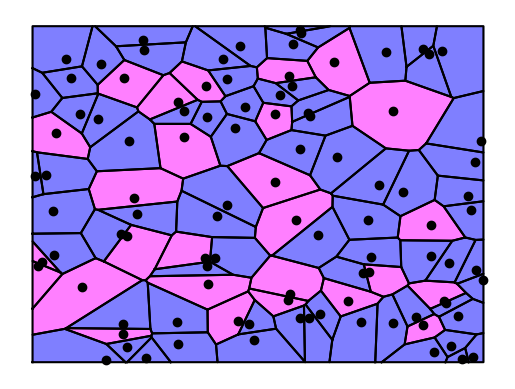

In [ ]:
fig, ax = plt.subplots()
ax.set_axis_off()

Cells = get_Voronoi_Cells_from_File("output/cellID_loc_vert.txt")
CIDs = get_IDs(Cells)
seeds = get_Seeds(Cells)
vertices = get_Vertices(Cells)

ims = []
for i in range(iterations):
    frame_artists = []
    for j in range(len(CIDs)):
        seed_ID, seed_loc, verts = CIDs[j], seeds[j], vertices[j]
        color_index = int(CA_state_data[i, seed_ID])

        # artist0, = ax.plot(seed_loc[0], seed_loc[1], "o", color="black", zorder=2)
        # frame_artists.append(artist0)
        artist1, = ax.plot(verts[0], verts[1], color="black")
        frame_artists.append(artist1)
        artist2, = ax.fill(verts[0], verts[1], color=colors[color_index], alpha=0.5)
        frame_artists.append(artist2)

    ims.append(frame_artists)
    
ani = animation.ArtistAnimation(fig, ims, blit=True)
ani.save("unnamed_2d_animation.gif", writer=animation.PillowWriter(fps=3))